In [1]:
# ---- configuration --------------------------------------------------------
from pathlib import Path
import os, shutil, sys, time, json

HF_REPO      = "mylyu/M4Raw_brain"
HF_REVISION  = "v1.6.0"          # pinned, immutable tag -> reproducible
SPLITS       = ["train", "val"]  # M4Raw 'val' (30 subjects) = the paper's test set
CONTRASTS    = ["T1", "T2"]
SCALES       = (2, 4)            # SR factors used in the paper
NUM_WORKERS  = os.cpu_count()

CACHE_DIR = Path("/kaggle/working/m4raw_cache")   # <- saved as the Kaggle Dataset
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# raw files go OUTSIDE /kaggle/working (they are not saved, and working is capped at 20 GB)
def free_gb(p):
    p = Path(p); p.mkdir(parents=True, exist_ok=True)
    return shutil.disk_usage(p).free / 1e9
for cand in ["/kaggle/temp", "/tmp/m4raw_raw"]:
    try:
        if free_gb(cand) > 15:
            RAW_DIR = Path(cand) / "M4Raw_raw"; break
    except OSError:
        pass
else:
    raise RuntimeError("No location with >15 GB free for the raw download")
RAW_DIR.mkdir(parents=True, exist_ok=True)
print("RAW_DIR  :", RAW_DIR, f"({free_gb(RAW_DIR):.0f} GB free)")
print("CACHE_DIR:", CACHE_DIR, f"({free_gb(CACHE_DIR):.0f} GB free)")

RAW_DIR  : /kaggle/temp/M4Raw_raw (1149 GB free)
CACHE_DIR: /kaggle/working/m4raw_cache (21 GB free)


In [2]:
!pip install -q -U huggingface_hub h5py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 9.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.6.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.1 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.


In [3]:
%%writefile /kaggle/working/m4raw_cache/m4raw_prep.py
"""
M4Raw preprocessing for SGF-MRI / DCAMSR reproduction.

Everything here is numpy + h5py only (no torch), so it runs on a Kaggle CPU
session and does not depend on DCAMSR's old torch==1.7 FFT API.

What it reproduces from the DCAMSR repo (Solor-pikachu/DCAMSR):
  * pairing:   T1 rep k  <->  T2 rep k of the same scan  (dataset/M4raw_get_train_val.py)
  * HR target: the `reconstruction_rss` stored in each H5 file
  * LR input:  per-coil  k-space -> ifft2c -> centre-crop image -> fft2c ->
               centre-crop k-space to (H/s, W/s) -> ifft2c -> |.| -> RSS over coils
               (experimental/DCAMSR/DCAMSR.py::DataTransform.__call__)
  * FFTs are centred and orthonormal, same as fastmri.math.fft2c/ifft2c
    (torch.fft(..., normalized=True) == numpy norm="ortho").
"""
from __future__ import annotations

import csv
import re
from pathlib import Path

import h5py
import numpy as np

# --------------------------------------------------------------------------- #
# FFT helpers (identical semantics to DCAMSR's fastmri/math.py)
# --------------------------------------------------------------------------- #
def fft2c(x: np.ndarray) -> np.ndarray:
    """Centred orthonormal 2D FFT over the last two axes (complex input)."""
    x = np.fft.ifftshift(x, axes=(-2, -1))
    x = np.fft.fft2(x, axes=(-2, -1), norm="ortho")
    return np.fft.fftshift(x, axes=(-2, -1))


def ifft2c(x: np.ndarray) -> np.ndarray:
    """Centred orthonormal 2D inverse FFT over the last two axes."""
    x = np.fft.ifftshift(x, axes=(-2, -1))
    x = np.fft.ifft2(x, axes=(-2, -1), norm="ortho")
    return np.fft.fftshift(x, axes=(-2, -1))


def center_crop(x: np.ndarray, shape) -> np.ndarray:
    """Centre crop over the last two axes (same arithmetic as fastMRI)."""
    h, w = shape
    assert 0 < h <= x.shape[-2] and 0 < w <= x.shape[-1], (x.shape, shape)
    h0 = (x.shape[-2] - h) // 2
    w0 = (x.shape[-1] - w) // 2
    return x[..., h0:h0 + h, w0:w0 + w]


def rss(x: np.ndarray, axis: int = 0) -> np.ndarray:
    return np.sqrt((np.abs(x) ** 2).sum(axis=axis))


# --------------------------------------------------------------------------- #
# DCAMSR-exact LR generation
# --------------------------------------------------------------------------- #
def dcamsr_crop_size(image_hw, target_hw):
    """DCAMSR crops to the target size, with its 'sFLAIR 203' guard."""
    crop = (target_hw[0], target_hw[1])
    if image_hw[0] < crop[1]:
        crop = (image_hw[0], image_hw[0])
    return crop


def dcamsr_lr_from_kspace(kspace_slice: np.ndarray, target_hw, scale: int) -> np.ndarray:
    """
    kspace_slice: (coils, H, W) complex  (multicoil, M4Raw)  or (H, W) (singlecoil)
    returns the LR magnitude image of shape (crop_h // scale, crop_w // scale)
    """
    img = ifft2c(kspace_slice)
    crop = dcamsr_crop_size(img.shape[-2:], target_hw)
    img = center_crop(img, crop)
    k = fft2c(img)
    k = center_crop(k, (crop[0] // scale, crop[1] // scale))
    lr = np.abs(ifft2c(k))
    if lr.ndim == 3:            # multicoil -> RSS over coils
        lr = np.sqrt((lr ** 2).sum(axis=0))
    return lr.astype(np.float32)


# --------------------------------------------------------------------------- #
# Pairing (same rule as DCAMSR's dataset/M4raw_get_train_val.py)
# --------------------------------------------------------------------------- #
NAME_RE = re.compile(r"^(?P<scan>\d{10})_(?P<seq>T1|T2|FLAIR)(?P<rep>\d{2})\.h5$")


def find_h5(root: Path) -> dict[str, Path]:
    """Map 'scanid_T101' -> path, searching recursively (zip/HF layouts differ)."""
    out = {}
    for p in Path(root).rglob("*.h5"):
        if NAME_RE.match(p.name):
            out[p.stem] = p
    return out


def build_pairs(files: dict[str, Path]):
    """Return sorted list of (T1_stem, T2_stem) pairs; also report orphans."""
    pairs, orphans = [], []
    for stem in sorted(files):
        m = NAME_RE.match(stem + ".h5")
        if m["seq"] != "T1":
            continue
        t2 = f"{m['scan']}_T2{m['rep']}"
        if t2 in files:
            pairs.append((stem, t2))
        else:
            orphans.append(stem)
    return pairs, orphans


def write_pair_csv(pairs, path: Path):
    with open(path, "w", newline="") as f:
        csv.writer(f).writerows(pairs)


def read_pair_csv(path: Path):
    with open(path) as f:
        return [tuple(r[:2]) for r in csv.reader(f) if r]


def compare_with_dcamsr(our_pairs, dcamsr_csv: Path, split: str):
    """Print how our split differs from the CSV DCAMSR (and SGF-MRI) used."""
    theirs = set(read_pair_csv(dcamsr_csv))
    ours = set(our_pairs)
    subj = lambda s: {a.split("_")[0] for a, _ in s}
    print(f"[{split}] ours: {len(ours)} pairs / {len(subj(ours))} subjects | "
          f"DCAMSR csv: {len(theirs)} pairs / {len(subj(theirs))} subjects")
    only_theirs = sorted(subj(theirs) - subj(ours))
    only_ours = sorted(subj(ours) - subj(theirs))
    print(f"[{split}]   subjects only in DCAMSR csv : {only_theirs}")
    print(f"[{split}]   subjects only in our files  : {only_ours}")
    return only_theirs, only_ours


# --------------------------------------------------------------------------- #
# Inspection helpers
# --------------------------------------------------------------------------- #
def inspect_file(path: Path) -> dict:
    with h5py.File(path, "r") as hf:
        k = hf["kspace"]
        info = {
            "keys": list(hf.keys()),
            "kspace_shape": k.shape,
            "kspace_dtype": str(k.dtype),
            "rss_shape": hf["reconstruction_rss"].shape if "reconstruction_rss" in hf else None,
            "attrs": {a: (v.decode() if isinstance(v, bytes) else v) for a, v in hf.attrs.items()},
        }
        mid = k.shape[0] // 2
        ks = k[mid]
        # which axis has unacquired (all-zero) lines -> phase-encode axis
        mag = np.abs(ks).sum(axis=0) if ks.ndim == 3 else np.abs(ks)
        info["zero_rows"] = int((mag.sum(axis=1) == 0).sum())
        info["zero_cols"] = int((mag.sum(axis=0) == 0).sum())
        if "reconstruction_rss" in hf:
            tgt = hf["reconstruction_rss"][mid]
            rec = center_crop(rss(ifft2c(ks), axis=0) if ks.ndim == 3 else np.abs(ifft2c(ks)), tgt.shape)
            info["rss_rel_err_mid_slice"] = float(np.linalg.norm(rec - tgt) / np.linalg.norm(tgt))
    return info


# --------------------------------------------------------------------------- #
# Cache writer: one small H5 per (T1, T2) pair
# --------------------------------------------------------------------------- #
def preprocess_pair(t1_path: Path, t2_path: Path, out_path: Path, scales=(2, 4)):
    """
    Writes:
      ref_hr  (S,H,W) float32  T1 reconstruction_rss   (reference, fully sampled)
      tar_hr  (S,H,W) float32  T2 reconstruction_rss   (target ground truth)
      ref_lr{s}, tar_lr{s}     DCAMSR-exact LR images for each scale s
    S = min(#slices T1, #slices T2) exactly like DCAMSR's SliceDataset.
    """
    with h5py.File(t1_path, "r") as h1, h5py.File(t2_path, "r") as h2:
        n = min(h1["kspace"].shape[0], h2["kspace"].shape[0])
        data = {}
        for tag, hf in (("ref", h1), ("tar", h2)):
            hr = hf["reconstruction_rss"][:n].astype(np.float32)
            data[f"{tag}_hr"] = hr
            for s in scales:
                data[f"{tag}_lr{s}"] = np.stack(
                    [dcamsr_lr_from_kspace(hf["kspace"][i], hr.shape[-2:], s) for i in range(n)]
                )
        attrs = {"ref_file": t1_path.name, "tar_file": t2_path.name, "num_slices": n,
                 "ref_max": float(h1.attrs.get("max", data["ref_hr"].max())),
                 "tar_max": float(h2.attrs.get("max", data["tar_hr"].max()))}

    out_path.parent.mkdir(parents=True, exist_ok=True)
    tmp = out_path.with_suffix(".tmp")
    with h5py.File(tmp, "w") as f:
        for k, v in data.items():
            f.create_dataset(k, data=v, chunks=(1,) + v.shape[1:])   # 1 slice per chunk -> fast reads
        for k, v in attrs.items():
            f.attrs[k] = v
    tmp.rename(out_path)          # atomic: a half-written file never looks finished
    return n

Writing /kaggle/working/m4raw_cache/m4raw_prep.py


In [4]:
%%writefile /kaggle/working/m4raw_cache/m4raw_dataset.py
"""
Training-time Dataset for the preprocessed M4Raw cache (T1 reference -> T2 target).

Two tasks, matching SGF-MRI Section 3.1 / 4:
  task="sr",    scale in {2, 4}   -> LR input = DCAMSR-exact LR image (precomputed)
  task="recon", accel in {4, 8}   -> zero-filled input  Y = |F^-1( M * F(X_tar) )|
                                     with a fastMRI RandomMaskFunc column mask

Normalisation follows DCAMSR exactly: per-slice instance norm using the mean/std
of the *degraded* input, the target is normalised with the same mean/std, the
reference with its own input's statistics, then everything is clamped to [-6, 6].

Usage on Kaggle:
    import sys; sys.path.append(CACHE_DIR)        # the cache dataset ships this file
    from m4raw_dataset import M4RawPairs, evaluate_volumes
    train_ds = M4RawPairs(CACHE_DIR, "train", task="sr", scale=4)
"""
from __future__ import annotations

import contextlib
from pathlib import Path

import h5py
import numpy as np

try:
    import torch
    from torch.utils.data import Dataset
except ImportError:          # lets the numpy logic be unit-tested without torch
    torch = None
    Dataset = object

from m4raw_prep import fft2c, ifft2c


# --------------------------------------------------------------------------- #
# fastMRI RandomMaskFunc, ported 1:1 (DCAMSR fastmri/data/subsample.py)
# --------------------------------------------------------------------------- #
@contextlib.contextmanager
def _temp_seed(rng, seed):
    if seed is None:
        yield
        return
    state = rng.get_state()
    rng.seed(seed)
    try:
        yield
    finally:
        rng.set_state(state)


class RandomMaskFunc:
    """Fully samples num_cols*center_fraction centre columns, the rest at random."""

    def __init__(self, center_fractions, accelerations):
        assert len(center_fractions) == len(accelerations)
        self.center_fractions, self.accelerations = center_fractions, accelerations
        self.rng = np.random.RandomState()

    def __call__(self, num_cols: int, seed=None) -> np.ndarray:
        with _temp_seed(self.rng, seed):
            choice = self.rng.randint(0, len(self.accelerations))
            cf, acc = self.center_fractions[choice], self.accelerations[choice]
            num_low = int(round(num_cols * cf))
            prob = (num_cols / acc - num_low) / (num_cols - num_low)
            mask = self.rng.uniform(size=num_cols) < prob
            pad = (num_cols - num_low + 1) // 2
            mask[pad:pad + num_low] = True
        return mask.astype(np.float32)


# fastMRI convention: 4x -> 8% centre, 8x -> 4% centre. NOT stated in the SGF-MRI paper.
DEFAULT_CENTER_FRACTION = {4: 0.08, 8: 0.04}


def _seed_from_name(name: str):
    """fastMRI's deterministic per-volume seed (same mask for a volume every epoch)."""
    return tuple(map(ord, name))


def _norm(x, mean, std, eps=1e-11):
    return np.clip((x - mean) / (std + eps), -6, 6).astype(np.float32)


# --------------------------------------------------------------------------- #
# Dataset
# --------------------------------------------------------------------------- #
class M4RawPairs(Dataset):
    def __init__(self, cache_dir, split, task="sr", scale=4, accel=4,
                 center_fraction=None, deterministic_mask=None, max_pairs=None):
        """
        split: "train" or "val"  (val = the paper's 30-subject test set)
        deterministic_mask: default False for train (new random mask every time,
            like DCAMSR use_seed=False) and True for val (fixed mask per volume).
        """
        assert task in ("sr", "recon")
        self.task, self.scale, self.accel = task, scale, accel
        self.files = sorted((Path(cache_dir) / split).glob("*.h5"))
        if max_pairs:
            self.files = self.files[:max_pairs]
        if not self.files:
            raise FileNotFoundError(f"No cache files in {Path(cache_dir) / split}")
        self.examples = []
        for f in self.files:
            with h5py.File(f, "r") as hf:
                self.examples += [(f, i) for i in range(int(hf.attrs["num_slices"]))]
        if task == "recon":
            cf = center_fraction or DEFAULT_CENTER_FRACTION[accel]
            self.mask_func = RandomMaskFunc([cf], [accel])
        self.deterministic = (split != "train") if deterministic_mask is None else deterministic_mask

    def __len__(self):
        return len(self.examples)

    # ---- degradations ------------------------------------------------------
    def _zero_filled(self, img, name):
        seed = _seed_from_name(name) if self.deterministic else None
        mask = self.mask_func(img.shape[-1], seed)           # sample columns (last axis)
        k = fft2c(img.astype(np.complex64)) * mask[None, :]
        return np.abs(ifft2c(k)).astype(np.float32), mask

    def __getitem__(self, i):
        path, s = self.examples[i]
        with h5py.File(path, "r") as hf:
            tar_hr = hf["tar_hr"][s]
            ref_hr = hf["ref_hr"][s]
            if self.task == "sr":
                tar_in = hf[f"tar_lr{self.scale}"][s]
                ref_in = hf[f"ref_lr{self.scale}"][s]
                mask = np.ones(1, np.float32)
            else:
                tar_in, mask = self._zero_filled(tar_hr, path.stem)
                ref_in = ref_hr          # reference is fully sampled in reconstruction

        # ddof=1: DCAMSR uses torch's .std(), which is the unbiased estimator
        mean, std = tar_in.mean(), tar_in.std(ddof=1)
        rmean, rstd = ref_in.mean(), ref_in.std(ddof=1)
        sample = {
            "input": _norm(tar_in, mean, std),     # degraded T2   (LR or zero-filled)
            "target": _norm(tar_hr, mean, std),    # clean T2
            "ref": _norm(ref_hr, rmean, rstd),     # clean T1      (DCAMSR "targetpd")
            "ref_in": _norm(ref_in, rmean, rstd),  # degraded T1   (DCAMSR "imagepd", SR only)
            "mask": mask,
            "mean": np.float32(mean), "std": np.float32(std),
            "fname": path.stem, "slice": s,
        }
        if torch is not None:
            for k in ("input", "target", "ref", "ref_in", "mask"):
                sample[k] = torch.from_numpy(sample[k])
        return sample


# --------------------------------------------------------------------------- #
# Metrics, exactly as DCAMSR/fastMRI compute them
# --------------------------------------------------------------------------- #
def evaluate_volumes(outputs: dict, targets: dict):
    """
    outputs/targets: {fname: np.ndarray (S,H,W)} in ORIGINAL intensity units,
    i.e. de-normalised with x * std + mean.
    PSNR uses data_range = volume max; SSIM is averaged over slices with the same
    data_range; both are averaged over volumes (fastmri/evaluate.py).
    """
    from skimage.metrics import peak_signal_noise_ratio, structural_similarity
    psnrs, ssims = [], []
    for name, gt in targets.items():
        pred = outputs[name]
        dr = gt.max()
        psnrs.append(peak_signal_noise_ratio(gt, pred, data_range=dr))
        ssims.append(np.mean([structural_similarity(g, p, data_range=dr) for g, p in zip(gt, pred)]))
    return {"psnr": float(np.mean(psnrs)), "psnr_std": float(np.std(psnrs)),
            "ssim": float(np.mean(ssims)), "ssim_std": float(np.std(ssims)),
            "n_volumes": len(psnrs)}

Writing /kaggle/working/m4raw_cache/m4raw_dataset.py


In [5]:
sys.path.insert(0, str(CACHE_DIR))
import importlib, m4raw_prep as P; importlib.reload(P)
import numpy as np, h5py

In [6]:
USE_ZENODO = False

patterns = [f"multicoil_{s}/*_{c}??.h5" for s in SPLITS for c in CONTRASTS]
patterns += ["SHA256SUMS*", "metadata/*"]

t0 = time.time()
if not USE_ZENODO:
    from huggingface_hub import snapshot_download
    snapshot_download(repo_id=HF_REPO, repo_type="dataset", revision=HF_REVISION,
                      local_dir=str(RAW_DIR), allow_patterns=patterns, max_workers=8)
else:
    # Official Zenodo record 8056074 (V1.6). Zips contain FLAIR too, so we extract only T1/T2.
    urls = {s: f"https://zenodo.org/records/8056074/files/M4RawV1.5_multicoil_{s}.zip?download=1"
            for s in SPLITS}
    for s, url in urls.items():
        z = RAW_DIR / f"{s}.zip"
        !wget -q -c "{url}" -O "{z}"
        !cd "{RAW_DIR}" && unzip -q -o "{z}" "*_T1??.h5" "*_T2??.h5" && rm "{z}"
print(f"download finished in {(time.time()-t0)/60:.1f} min")
!du -sh "{RAW_DIR}"

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 971 files:   0%|          | 0/971 [00:00<?, ?it/s]

download finished in 3.0 min
11G	/kaggle/temp/M4Raw_raw


In [7]:
import hashlib
sums = sorted(RAW_DIR.glob("SHA256SUMS*"))
if not sums:
    print("No SHA256SUMS file found (expected with the Zenodo fallback) - skipping.")
else:
    expected = {}
    for line in sums[0].read_text().splitlines():
        parts = line.strip().split()
        if len(parts) >= 2:
            expected[Path(parts[-1].lstrip("*")).as_posix().lstrip("./")] = parts[0].lower()
    def sha(p, bs=1 << 22):
        h = hashlib.sha256()
        with open(p, "rb") as f:
            for b in iter(lambda: f.read(bs), b""): h.update(b)
        return h.hexdigest()
    from concurrent.futures import ThreadPoolExecutor
    local = sorted(RAW_DIR.rglob("*.h5"))
    rel = [p.relative_to(RAW_DIR).as_posix() for p in local]
    with ThreadPoolExecutor(NUM_WORKERS) as ex:
        got = list(ex.map(sha, local))
    bad = [r for r, g in zip(rel, got) if r in expected and expected[r] != g]
    missing = [r for r in rel if r not in expected]
    print(f"checked {len(rel)} files | mismatched: {len(bad)} | not listed in SHA256SUMS: {len(missing)}")
    assert not bad, bad[:5]

checked 948 files | mismatched: 0 | not listed in SHA256SUMS: 0


In [8]:
files = {s: P.find_h5(RAW_DIR / f"multicoil_{s}") for s in SPLITS}
for s in SPLITS:
    n_t1 = sum(1 for k in files[s] if "_T1" in k); n_t2 = sum(1 for k in files[s] if "_T2" in k)
    print(f"{s}: {len(files[s])} files  (T1={n_t1}, T2={n_t2})")

for name in ["2022061001_T101", "2022061001_T201"]:
    p = files["train"].get(name) or next(iter(files["train"].values()))
    info = P.inspect_file(p)
    print("\n", p.name, json.dumps({k: str(v) for k, v in info.items()}, indent=1))

train: 768 files  (T1=384, T2=384)
val: 180 files  (T1=90, T2=90)

 2022061001_T101.h5 {
 "keys": "['ismrmrd_header', 'kspace', 'reconstruction_rss']",
 "kspace_shape": "(18, 4, 256, 256)",
 "kspace_dtype": "complex64",
 "rss_shape": "(18, 256, 256)",
 "attrs": "{'acquisition': 'AXT1', 'max': np.float64(150.6504233871875), 'patient_id': '2316dc9985fffbccde16179aef26124f'}",
 "zero_rows": "0",
 "zero_cols": "61",
 "rss_rel_err_mid_slice": "8.81906601080118e-08"
}

 2022061001_T201.h5 {
 "keys": "['ismrmrd_header', 'kspace', 'reconstruction_rss']",
 "kspace_shape": "(18, 4, 256, 256)",
 "kspace_dtype": "complex64",
 "rss_shape": "(18, 256, 256)",
 "attrs": "{'acquisition': 'AXT2', 'max': np.float64(112.11752607673905), 'patient_id': '2316dc9985fffbccde16179aef26124f'}",
 "zero_rows": "0",
 "zero_cols": "61",
 "rss_rel_err_mid_slice": "8.559437247868118e-08"
}


In [9]:
!wget -q -O /kaggle/working/DCAMSR_M4Raw_train.csv https://raw.githubusercontent.com/Solor-pikachu/DCAMSR/f42c64d79a5595fd6e9406fccad23d72d20191d4/dataset/M4Raw_train_split_less.csv
!wget -q -O /kaggle/working/DCAMSR_M4Raw_val.csv   https://raw.githubusercontent.com/Solor-pikachu/DCAMSR/f42c64d79a5595fd6e9406fccad23d72d20191d4/dataset/M4Raw_val_split_less.csv

pairs = {}
for s in SPLITS:
    pairs[s], orphans = P.build_pairs(files[s])
    assert not orphans, f"T1 files without a T2 partner: {orphans}"
    P.write_pair_csv(pairs[s], CACHE_DIR / f"pairs_{s}.csv")
    P.compare_with_dcamsr(pairs[s], Path(f"/kaggle/working/DCAMSR_M4Raw_{s}.csv"), s)

n_sub = {s: len({a.split('_')[0] for a, _ in pairs[s]}) for s in SPLITS}
print("\nsubjects:", n_sub, "| paper says train=128, test=30")
assert n_sub == {"train": 128, "val": 30}, "subject counts differ from the paper!"

[train] ours: 384 pairs / 128 subjects | DCAMSR csv: 384 pairs / 128 subjects
[train]   subjects only in DCAMSR csv : ['2022062709']
[train]   subjects only in our files  : ['2023053001']
[val] ours: 90 pairs / 30 subjects | DCAMSR csv: 90 pairs / 30 subjects
[val]   subjects only in DCAMSR csv : ['2022062708']
[val]   subjects only in our files  : ['2023053002']

subjects: {'train': 128, 'val': 30} | paper says train=128, test=30


In [10]:
from concurrent.futures import ProcessPoolExecutor
from tqdm.auto import tqdm

def job(args):
    s, t1, t2 = args
    out = CACHE_DIR / s / f"{t1.split('_')[0]}_rep{t1[-2:]}.h5"
    if out.exists():
        return 0
    return P.preprocess_pair(files[s][t1], files[s][t2], out, SCALES)

jobs = [(s, t1, t2) for s in SPLITS for t1, t2 in pairs[s]]
t0 = time.time()
with ProcessPoolExecutor(NUM_WORKERS) as ex:
    list(tqdm(ex.map(job, jobs, chunksize=4), total=len(jobs)))
print(f"preprocessing done in {(time.time()-t0)/60:.1f} min")
!du -sh {CACHE_DIR}/train {CACHE_DIR}/val

  0%|          | 0/474 [00:00<?, ?it/s]

preprocessing done in 32.9 min
4.5G	/kaggle/working/m4raw_cache/train
1.1G	/kaggle/working/m4raw_cache/val


In [11]:
tot = {}
for s in SPLITS:
    fs = sorted((CACHE_DIR / s).glob("*.h5"))
    slices = 0
    for f in fs:
        with h5py.File(f) as hf:
            n = hf.attrs["num_slices"]; slices += n
            H, W = hf["tar_hr"].shape[1:]
            assert hf["ref_hr"].shape == (n, H, W)
            for sc in SCALES:
                assert hf[f"tar_lr{sc}"].shape == (n, H // sc, W // sc), (f, sc)
            assert np.isfinite(hf["tar_hr"][:]).all()
    tot[s] = (len(fs), slices)
    print(f"{s}: {len(fs)} pair-volumes, {slices} slices, image size {H}x{W}")
assert tot["train"][0] == len(pairs["train"]) and tot["val"][0] == len(pairs["val"])

# spot-check: cached LR == DCAMSR transform recomputed from raw k-space
f = sorted((CACHE_DIR / "val").glob("*.h5"))[0]
with h5py.File(f) as hf:
    t2_raw = files["val"][hf.attrs["tar_file"].replace(".h5", "")]
    mid = int(hf.attrs["num_slices"]) // 2
    cached = hf["tar_lr4"][mid]
with h5py.File(t2_raw) as hr:
    fresh = P.dcamsr_lr_from_kspace(hr["kspace"][mid], hr["reconstruction_rss"].shape[-2:], 4)
print("max |cached - recomputed| =", np.abs(cached - fresh).max())

train: 384 pair-volumes, 6912 slices, image size 256x256
val: 90 pair-volumes, 1620 slices, image size 256x256
max |cached - recomputed| = 0.0


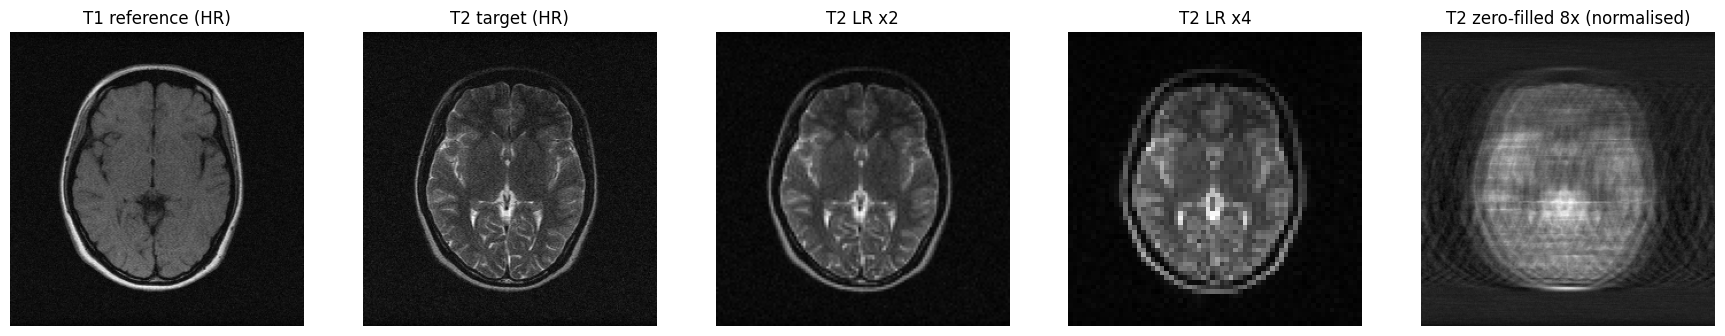

In [12]:
import matplotlib.pyplot as plt
with h5py.File(f) as hf:
    s = hf.attrs["num_slices"] // 2
    imgs = [hf["ref_hr"][s], hf["tar_hr"][s], hf["tar_lr2"][s], hf["tar_lr4"][s]]
from m4raw_dataset import M4RawPairs
zf = M4RawPairs(CACHE_DIR, "val", task="recon", accel=8, max_pairs=1)[s]["input"]
titles = ["T1 reference (HR)", "T2 target (HR)", "T2 LR x2", "T2 LR x4", "T2 zero-filled 8x (normalised)"]
fig, ax = plt.subplots(1, 5, figsize=(22, 5))
for a, im, t in zip(ax, imgs + [np.asarray(zf)], titles):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.show()

In [13]:
manifest = {
    "source": f"huggingface.co/datasets/{HF_REPO}@{HF_REVISION}" if not USE_ZENODO else "zenodo.org/records/8056074",
    "reference_contrast": "T1", "target_contrast": "T2",
    "splits": {s: {"pair_volumes": tot[s][0], "slices": int(tot[s][1]),
                   "subjects": n_sub[s]} for s in SPLITS},
    "arrays": {"ref_hr/tar_hr": "reconstruction_rss, float32 (S,H,W)",
               "ref_lr{s}/tar_lr{s}": "DCAMSR-exact LR (coil k-space centre crop -> RSS)"},
    "note": "'val' is the 30-subject set the paper (via DCAMSR) uses for testing.",
}
(CACHE_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps(manifest, indent=2))
shutil.rmtree(RAW_DIR, ignore_errors=True)        # raw data is not needed any more
for p in Path("/kaggle/working").glob("DCAMSR_M4Raw_*.csv"): p.unlink()
!du -sh /kaggle/working

{
  "source": "huggingface.co/datasets/mylyu/M4Raw_brain@v1.6.0",
  "reference_contrast": "T1",
  "target_contrast": "T2",
  "splits": {
    "train": {
      "pair_volumes": 384,
      "slices": 6912,
      "subjects": 128
    },
    "val": {
      "pair_volumes": 90,
      "slices": 1620,
      "subjects": 30
    }
  },
  "arrays": {
    "ref_hr/tar_hr": "reconstruction_rss, float32 (S,H,W)",
    "ref_lr{s}/tar_lr{s}": "DCAMSR-exact LR (coil k-space centre crop -> RSS)"
  },
  "note": "'val' is the 30-subject set the paper (via DCAMSR) uses for testing."
}
5.5G	/kaggle/working
